# 02 · Vanilla Autoencoder

**Arsitektur:** encoder 784 → 256 → 64, decoder 64 → 256 → 784.
Arsitektur encoder ini **sengaja dibuat sama persis** dengan MLP Classifier (notebook 01). Jadi pada notebook 08, satu-satunya perbedaan antara z_AE dan z_MLP adalah **loss function** yang melatihnya.

**Loss:** MSE per piksel → L = (1/D) ‖x − x̂‖²

> **Ide utama (loss → visual):**
> MSE menghukum selisih per piksel. Kalau model "ragu" di mana tepatnya sebuah garis atau tekstur berada, pilihan paling aman untuk MSE adalah **rata-rata** dari semua kemungkinan. Rata-rata beberapa versi gambar = gambar **buram**. Secara matematis, decoder belajar mendekati 𝔼[x | z].
> Selain itu, loss ini **tidak mengatur bentuk ruang laten**. Kode z dari data latih bisa tersebar acak dengan banyak "wilayah kosong" (*latent voids*) di antaranya. Akibatnya interpolasi dan sampling acak sering menghasilkan gambar rusak.

In [1]:
%run ./00_helpers.ipynb

device = cuda | dataset = fashion_mnist | QUICK = False
folder proyek = c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN
hasil -> c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results
Helpers siap ✔


c:\Users\Derry\Anaconda\envs\deep-learning\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load Dataset

In [2]:
set_seed()
splits = load_splits()
loaders = make_loaders(splits)
x_train, y_train = splits["train"]
x_test, y_test = splits["test"]

Jumlah data: {'train': 56000, 'val': 7000, 'test': 7000}


## 2. Hyperparameter

In [3]:
HIDDEN_DIM = 256
LATENT_DIM = 64
MAX_EPOCHS = n_epochs(30)
LEARNING_RATE = 1e-3

## 3. Model

In [4]:
class AutoEncoder(nn.Module):
    # Encoder: x (784) -> h = ReLU(W1 x) (256) -> z = ReLU(W2 h) (64)
    # Decoder: z (64)  -> ReLU (256) -> Sigmoid (784)
    def __init__(self, hidden=256, latent=64):
        super().__init__()
        self.enc1 = nn.Linear(IMG_SIZE, hidden)
        self.enc2 = nn.Linear(hidden, latent)
        self.decoder = nn.Sequential(
            nn.Linear(latent, hidden), nn.ReLU(),
            nn.Linear(hidden, IMG_SIZE), nn.Sigmoid())

    def encode(self, x, return_hidden=False):
        h = F.relu(self.enc1(x.flatten(1)))
        z = F.relu(self.enc2(h))
        return (z, h) if return_hidden else z

    def decode(self, z):
        return self.decoder(z).view(-1, *IMG_SHAPE)

    def forward(self, x):
        z, h = self.encode(x, return_hidden=True)
        return self.decode(z), z, h

model = AutoEncoder(HIDDEN_DIM, LATENT_DIM).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(model)
print("Jumlah parameter:", count_params(model))

AutoEncoder(
  (enc1): Linear(in_features=784, out_features=256, bias=True)
  (enc2): Linear(in_features=256, out_features=64, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)
Jumlah parameter: 435536


## 4. Loss Function

In [5]:
def loss_fn(model, x):
    x_hat, z, h = model(x)
    mse = F.mse_loss(x_hat, x)                 # (1/D) ||x - x_hat||^2, dirata-rata per batch
    return mse, {"loss": mse.item(), "mse": mse.item()}

## 5. Training

In [6]:
history = {"model": "vanilla_ae", "params": count_params(model), "epoch": [], "iter_loss": [],
           "epoch_time_s": [], "train": [], "val": []}

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    t0 = time.perf_counter()
    sums, n = {}, 0
    for it, (x, _) in enumerate(loaders["train"]):
        x = x.to(device)
        loss, logs = loss_fn(model, x)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        for k, v in logs.items():
            sums[k] = sums.get(k, 0.0) + v
        n += 1
        if it % 10 == 0:
            history["iter_loss"].append(logs["loss"])
    sync()
    history["epoch_time_s"].append(time.perf_counter() - t0)
    history["train"].append({k: v / n for k, v in sums.items()})

    # validasi
    model.eval()
    vsums, vn = {}, 0
    with torch.no_grad():
        for x, _ in loaders["val"]:
            _, logs = loss_fn(model, x.to(device))
            for k, v in logs.items():
                vsums[k] = vsums.get(k, 0.0) + v
            vn += 1
    history["val"].append({k: v / vn for k, v in vsums.items()})
    history["epoch"].append(epoch)
    tr = history["train"][-1]
    print(f"Epoch[{epoch}/{MAX_EPOCHS}] " + "  ".join(f"{k}: {v:.4f}" for k, v in tr.items())
          + f"  | val loss: {history['val'][-1]['loss']:.4f}  ({history['epoch_time_s'][-1]:.1f}s)")

torch.save({"model": model.state_dict()}, CKPT_DIR / "vanilla_ae.pt")

Epoch[1/30] loss: 0.0346  mse: 0.0346  | val loss: 0.0198  (1.7s)
Epoch[2/30] loss: 0.0177  mse: 0.0177  | val loss: 0.0169  (1.5s)
Epoch[3/30] loss: 0.0152  mse: 0.0152  | val loss: 0.0145  (1.2s)
Epoch[4/30] loss: 0.0136  mse: 0.0136  | val loss: 0.0132  (1.1s)
Epoch[5/30] loss: 0.0126  mse: 0.0126  | val loss: 0.0126  (1.5s)
Epoch[6/30] loss: 0.0118  mse: 0.0118  | val loss: 0.0118  (1.5s)
Epoch[7/30] loss: 0.0113  mse: 0.0113  | val loss: 0.0113  (1.5s)
Epoch[8/30] loss: 0.0108  mse: 0.0108  | val loss: 0.0109  (1.5s)
Epoch[9/30] loss: 0.0104  mse: 0.0104  | val loss: 0.0106  (1.5s)
Epoch[10/30] loss: 0.0101  mse: 0.0101  | val loss: 0.0103  (1.4s)
Epoch[11/30] loss: 0.0098  mse: 0.0098  | val loss: 0.0100  (1.4s)
Epoch[12/30] loss: 0.0096  mse: 0.0096  | val loss: 0.0098  (1.6s)
Epoch[13/30] loss: 0.0094  mse: 0.0094  | val loss: 0.0096  (1.4s)
Epoch[14/30] loss: 0.0092  mse: 0.0092  | val loss: 0.0095  (1.6s)
Epoch[15/30] loss: 0.0091  mse: 0.0091  | val loss: 0.0093  (1.6s)
Epoc

## 6. Plot Loss History

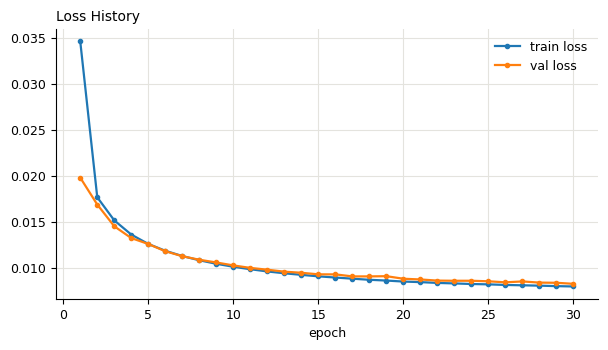

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(history["epoch"], [e["loss"] for e in history["train"]], "-o", ms=3, label="train loss")
ax.plot(history["epoch"], [e["loss"] for e in history["val"]], "-o", ms=3, label="val loss")
ax.set_title("Loss History", loc="left"); ax.set_xlabel("epoch"); ax.legend()
plt.show()

## 7. Evaluasi pada Test Set

- **Metrik rekonstruksi:** MSE, PSNR, SSIM pada seluruh Test Set.
- **Latency:** waktu encode + decode untuk 64 citra uji dan untuk 1 citra.

In [8]:
model.eval()
recon_fn = lambda x: model(x)[0]

metrics = {"model": "vanilla_ae", "params": count_params(model), "latent_dim": LATENT_DIM,
           "train_time_per_epoch_s": float(np.mean(history["epoch_time_s"]))}
metrics.update(reconstruction_metrics(recon_fn, x_test))

x64, x1 = x_test[:LATENCY_BATCH].to(device), x_test[:1].to(device)
metrics["latency_ms_batch64"], metrics["latency_ms_batch64_std"] = measure_latency(lambda: recon_fn(x64))
metrics["latency_ms_batch1"], metrics["latency_ms_batch1_std"] = measure_latency(lambda: recon_fn(x1))
metrics["latency_mode"] = "rekonstruksi (encode + decode)"

print(f"Test MSE  : {metrics['mse']:.5f}")
print(f"Test PSNR : {metrics['psnr']:.2f} dB")
print(f"Test SSIM : {metrics['ssim']:.4f}")
print(f"Latency   : {metrics['latency_ms_batch64']:.2f} ms / batch 64 | {metrics['latency_ms_batch1']:.2f} ms / 1 sampel")

Test MSE  : 0.00819
Test PSNR : 21.93 dB
Test SSIM : 0.7417
Latency   : 0.35 ms / batch 64 | 0.35 ms / 1 sampel


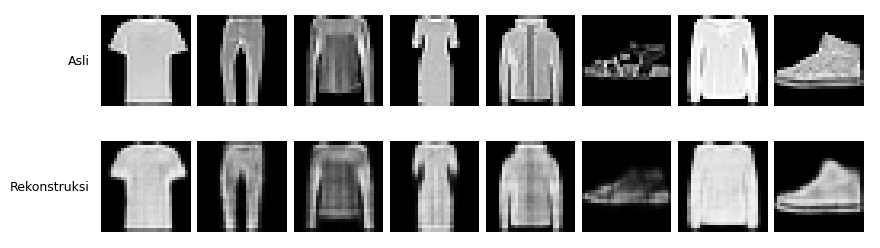

In [9]:
# Visual: baris atas = citra asli, baris bawah = rekonstruksi
x_fix, y_fix = fixed_examples(splits)
with torch.no_grad():
    recon_fix = recon_fn(x_fix.to(device)).cpu()
fig, axes = plt.subplots(2, 1, figsize=(10, 3))
show_imgs(axes[0], x_fix, label="Asli")
show_imgs(axes[1], recon_fix, label="Rekonstruksi")
plt.show()

## 8. Analisis Tambahan untuk Pertanyaan Penelitian

### 8a. Struktur fitur hidden layer (Q2)
Berapa persen dari 256 neuron hidden yang menyala untuk setiap gambar? Bagaimana bentuk filter W1-nya?

{'active_frac_mean': 0.5272383093833923, 'active_units_per_sample': 134.97300720214844, 'dead_units': 86, 'l1_per_sample': 255.47093200683594}


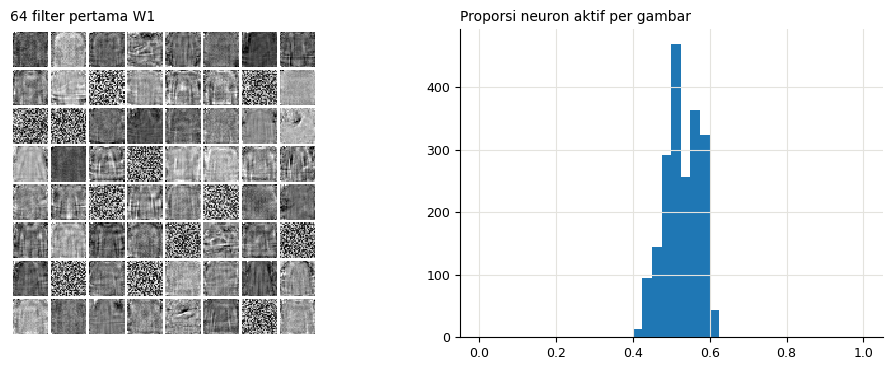

In [10]:
with torch.no_grad():
    _, h_test = model.encode(x_test[:2000].to(device), return_hidden=True)
act = (h_test > 1e-3).float()
sparsity = {"active_frac_mean": float(act.mean()),
            "active_units_per_sample": float(act.sum(1).mean()),
            "dead_units": int((act.sum(0) == 0).sum()),
            "l1_per_sample": float(h_test.abs().sum(1).mean())}
active_frac_per_image = act.mean(1).cpu()
W1_filters = model.enc1.weight[:64].detach().cpu().view(64, 1, 28, 28)
W1_filters = (W1_filters - W1_filters.amin((1, 2, 3), keepdim=True)) / (
    W1_filters.amax((1, 2, 3), keepdim=True) - W1_filters.amin((1, 2, 3), keepdim=True) + 1e-8)
print(sparsity)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
show_imgs(axes[0], W1_filters, nrow=8, title="64 filter pertama W1")
axes[1].hist(active_frac_per_image.numpy(), bins=40, range=(0, 1))
axes[1].set_title("Proporsi neuron aktif per gambar", loc="left")
plt.show()

### 8b. Deteksi anomali dengan reconstruction error (Q6 bagian 1)

In [11]:
anomaly = anomaly_auroc(recon_fn, x_test)
print(anomaly)

{'auroc': 0.7287426020408163, 'err_normal_mean': 0.008188819512724876, 'err_defect_mean': 0.01314280740916729, 'err_ratio': 1.6049697399139404}


### 8c. Variasi intra-kelas (dipakai sebagai pembanding di notebook 08, Tahap 4)

In [12]:
recon_test = apply_batched(recon_fn, x_test)
intra = intra_class_analysis(recon_test, x_test, y_test)
print(intra)

{'var_ratio': 0.8331017017364502, 'closer_to_class_mean': 0.007571428548544645}


### 8d. Interpolasi laten (Figur 4 & Q4)
z_A = kode laten citra uji kelas A, z_B = kode laten citra uji kelas B. `bank` = kode laten 5.000 data latih, dipakai untuk mendeteksi *latent voids*.

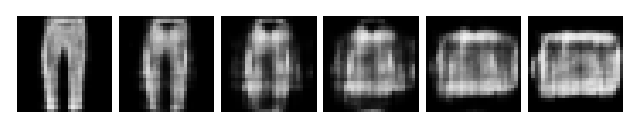

{'model': 'vanilla_ae', 'alpha': 0.0, 'nn_dist_ratio': 1.2112038135528564, 'classifier_max_conf': 1.0, 'pixel_change_from_prev': 0.0}
{'model': 'vanilla_ae', 'alpha': 0.2, 'nn_dist_ratio': 1.3163073062896729, 'classifier_max_conf': 0.9999622106552124, 'pixel_change_from_prev': 0.051141560077667236}
{'model': 'vanilla_ae', 'alpha': 0.4, 'nn_dist_ratio': 1.6555684804916382, 'classifier_max_conf': 0.6237279176712036, 'pixel_change_from_prev': 0.057645831257104874}
{'model': 'vanilla_ae', 'alpha': 0.6, 'nn_dist_ratio': 1.609163522720337, 'classifier_max_conf': 0.8935211300849915, 'pixel_change_from_prev': 0.0740094929933548}
{'model': 'vanilla_ae', 'alpha': 0.8, 'nn_dist_ratio': 1.3032689094543457, 'classifier_max_conf': 0.9997754693031311, 'pixel_change_from_prev': 0.08085301518440247}
{'model': 'vanilla_ae', 'alpha': 1.0, 'nn_dist_ratio': 1.410722255706787, 'classifier_max_conf': 0.999998927116394, 'pixel_change_from_prev': 0.08203661441802979}


In [13]:
clf = load_mlp_classifier()
xa, xb = interp_endpoints(splits)
enc = model.encode
with torch.no_grad():
    za, zb = enc(xa.to(device)), enc(xb.to(device))
    bank = apply_batched(enc, x_train[:5000]).to(device)
interp_imgs, interp_rows = interpolation_record("vanilla_ae", za, zb, model.decode, clf, bank)
fig, ax = plt.subplots(figsize=(8, 1.6)); show_imgs(ax, interp_imgs); plt.show()
for r in interp_rows:
    print(r)

### 8e. Uji sampling acak di ruang laten AE (Q4)
Autoencoder deterministik **tidak punya prior**. Coba ambil z ~ N(μ_z, diag σ_z²) dari statistik kode laten citra uji, lalu decode. Karena ruang latennya penuh "lubang", hasilnya biasanya rusak. Inilah sebabnya FID untuk AE ditulis *N/A (Latent Voids)* di tabel.

{'frac_negative_entries': 0.02446874976158142, 'frac_zero_entries_real': 0.33943304419517517, 'fid': 165.29016430951333, 'mode_coverage': {'class_hist': [0.12479999661445618, 0.03959999978542328, 0.13199999928474426, 0.12919999659061432, 0.15440000593662262, 0.05860000103712082, 0.11599999666213989, 0.04919999837875366, 0.1703999936580658, 0.025800000876188278], 'entropy_norm': 0.9415227770805359, 'modes_covered': 10}}


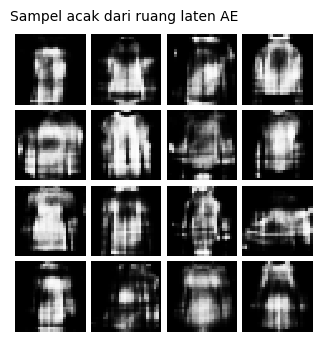

In [14]:
with torch.no_grad():
    z_test = apply_batched(model.encode, x_test)
z_rand, zstats = gaussian_fit_sampling(z_test, FID_NUM_SAMPLES)
samples = apply_batched(model.decode, z_rand)
gauss_fit = {**zstats, "fid": compute_fid(samples, splits), "mode_coverage": mode_coverage(samples, clf)}
print(gauss_fit)
fig, ax = plt.subplots(figsize=(4, 4)); show_imgs(ax, samples[:16], nrow=4, title="Sampel acak dari ruang laten AE"); plt.show()

## 9. Simpan Hasil untuk Laporan

In [15]:
metrics["stability"] = stability_summary(history)
metrics["anomaly"] = anomaly
metrics["hparams"] = {"epochs": len(history["epoch"]), "lr": LEARNING_RATE, "batch_size": BATCH_SIZE,
                      "hidden_dim": HIDDEN_DIM, "latent_dim": LATENT_DIM}
metrics["sparsity"] = sparsity
metrics["gaussian_fit_sampling"] = gauss_fit
metrics["intra_class"] = intra
save_results("vanilla_ae", metrics, artifacts={"recon_fixed": recon_fix, "x_fixed": x_fix, "interp_imgs": interp_imgs, "interp_rows": interp_rows, "W1_filters": W1_filters, "active_frac_per_image": active_frac_per_image}, history=history)

Hasil 'vanilla_ae' tersimpan di c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results/
